# Jigsaw puzzle

The task is to reconstruct a complete RGB image of size 96×96 from a set of 9 scrambled image patches of size 28×28×3. The patches originate from a 3×3 partition of the original image, but their spatial arrangement is unknown and part of the border information has been removed through erosion, making the reconstruction problem ambiguous. The model must therefore infer both the correct relative placement of the patches and the missing visual content required to produce a coherent, artifact-free reconstruction of the original image.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers, models
from keras.utils import PyDataset
import tensorflow as tf
import gdown

We use the stanford stl10 dataset, containing 100K color images at resolution (96,96), covering 10 classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck.

Downloading the dataset is time consuming. We recommend to save a local copy.



In [2]:
N_IMAGES = 100000  # set to None to load all 100K

def download_and_load_stl10(n=None):
    # Download and extract the dataset
    path = tf.keras.utils.get_file(
        'stl10_binary.tar.gz',
        origin='http://ai.stanford.edu/~acoates/stl10/stl10_binary.tar.gz',
        extract=True
    )

    # Get the base directory (typically ~/.keras/datasets/)
    base_dir = os.path.dirname(path)


    data_dir = os.path.join(base_dir, 'stl10_binary_extracted', 'stl10_binary')
    filepath = os.path.join(data_dir, 'unlabeled_X.bin')

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Could not find the binary file at {filepath}")

    print(f"Loading data from: {filepath}")

    with open(filepath, 'rb') as f:
        # STL-10 unlabeled set contains 100,000 images
        # Data is stored as uint8, (N, C, H, W)
        data = np.fromfile(f, dtype=np.uint8)
        images = np.reshape(data, (-1, 3, 96, 96))

        # Transpose from (N, C, H, W) to (N, H, W, C) for standard image processing
        images = np.transpose(images, (0, 3, 2, 1))

    if n is not None:
        images = images[:n]

    return images

# This is a custom class. We declare that when we define a PatchGenerator object, it will need
# and take data like images, batch_size etc. and store them in the attributes we define below.
class PatchGenerator(PyDataset):
    def __init__(self, images, batch_size=32, patch_size=32, crop_size=28, shuffle=True, **kwargs):
        super().__init__(**kwargs)
        self.images = images.astype("float32") / 255.0  # Normalize on the fly or pre-normalize
        self.batch_size = batch_size
        self.patch_size = patch_size
        self.crop_size = crop_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.images))
        if self.shuffle:
            np.random.shuffle(self.indices)

    # The __len__ method defines what happens when we call len(X) where X is a PathGenerator object.
    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))


    """ Let's say we have a PatchGenerator object G. We need to define what does it mean to do
    G[i]. In this case, we return X,Y where X is an array of shape (32,9,28,28,3) =
    (batch_size,number of patches, eroded resolution side, eroded resolution side, channels),
    while Y is the array of the original images, i.e. an array of shape
    (32,96,96,3) = (batch_size, full resolution side of orignal image, full resolution side of original image, channels).
    """
    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        actual_batch_size = len(batch_indices)

        X = np.zeros((actual_batch_size, 9, self.crop_size, self.crop_size, 3), dtype="float32")
        Y = np.zeros((actual_batch_size, 96, 96, 3), dtype="float32")

        for i, img_idx in enumerate(batch_indices):
            full_img = self.images[img_idx]
            Y[i] = full_img
            patches = []

            # Extract 9 patches in a 3x3 grid
            for r in range(3):
                for c in range(3):
                    # Define grid coordinates
                    y_start, x_start = r * self.patch_size, c * self.patch_size
                    patch = full_img[y_start : y_start + self.patch_size,
                                     x_start : x_start + self.patch_size, :]

                    # Center Crop to avoid edge-matching shortcuts (we could go random crop)
                    margin = (self.patch_size - self.crop_size) // 2
                    patch = patch[margin : margin + self.crop_size,
                                  margin : margin + self.crop_size, :]
                    patches.append(patch)

            # Create a permutation (0-8)
            order = np.random.permutation(9)

            for slot_idx, original_pos in enumerate(order):
                X[i, slot_idx] = patches[original_pos]

        return X, Y


    # This is another method provided by Keras PyDataset. It is called at the end of each training epoch
    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


In [3]:
# Trigger the download and loading
images = download_and_load_stl10(n=N_IMAGES)
print(f"Successfully loaded {images.shape[0]} images.")

2640397119/2640397119 ━━━━━━━━━━━━━━━━━━━━ 214s 0us/step
Loading data from: /root/.keras/datasets/stl10_binary_extracted/stl10_binary/unlabeled_X.bin
Successfully loaded 100000 images.


In [4]:
print(images.shape)

(100000, 96, 96, 3)


In [5]:
# Slightly modified this cell to work also with smaller number of
# images, for time purposes
n_train = int(0.8 * N_IMAGES)
n_val   = int(0.1 * N_IMAGES)

train_images = images[:n_train]
val_images   = images[n_train : n_train + n_val]
test_images  = images[n_train + n_val:]

print(f'train : {train_images.shape}')
print(f'val   : {val_images.shape}')
print(f'test  : {test_images.shape}')

train : (80000, 96, 96, 3)
val   : (10000, 96, 96, 3)
test  : (10000, 96, 96, 3)


In [6]:
train_generator = PatchGenerator(train_images, batch_size=8)
val_generator   = PatchGenerator(val_images,   batch_size=8)
test_generator  = PatchGenerator(test_images,  batch_size=8)

Let us inspect the dataset.

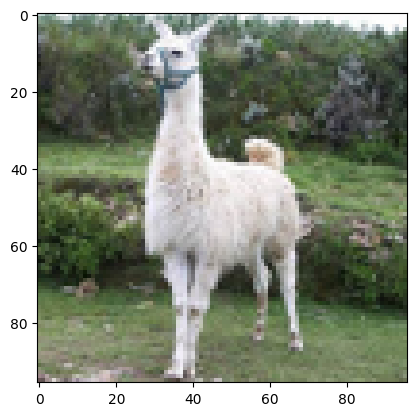

In [7]:
n = np.random.randint(0, test_images.shape[0])
plt.imshow(test_images[n])

Let us now visualize the puzzle

In [8]:
def plot_puzzle(patches, ordering=None):
    """
    Plots jigsaw patches on a 96x96 canvas.

    Args:
        patches: Array of shape (9, 28, 28, 3)
        ordering: Optional array of shape (9,) or (1, 9) containing
                  the destination grid indices.
    """
    # 1. Handle ordering: if None, use [0, 1, 2... 8]
    if ordering is None:
        order = np.arange(9)
    else:
        order = np.array(ordering).flatten()

    # 2. Setup canvas (96x96x3)
    # Use 1.0 for float images (0.0-1.0) or 255 for uint8 images
    if patches.dtype == np.uint8:
        canvas = np.full((96, 96, 3), 255, dtype=np.uint8)
    else:
        canvas = np.ones((96, 96, 3), dtype=np.float32)

    cell_dim = 32
    patch_dim = 28
    margin = (cell_dim - patch_dim) // 2

    # 3. Place patches
    for i in range(9):
        # Determine destination grid position
        grid_pos = order[i]

        row = grid_pos // 3
        col = grid_pos % 3

        # Calculate canvas pixel coordinates
        y_start = (row * cell_dim) + margin
        y_end = y_start + patch_dim
        x_start = (col * cell_dim) + margin
        x_end = x_start + patch_dim

        # Insert patch i into its grid_pos
        canvas[y_start:y_end, x_start:x_end] = patches[i]

    # 4. Display
    plt.figure(figsize=(5, 5))
    plt.imshow(canvas)
    plt.axis('off')
    plt.show()

In [9]:
a, b = test_generator.__getitem__(1)

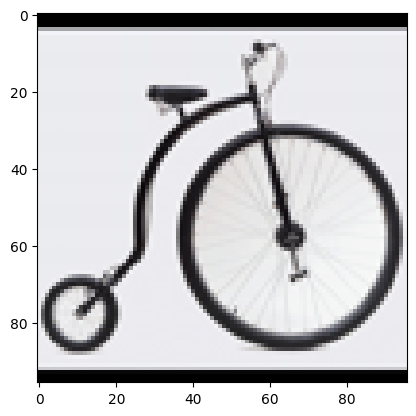

In [10]:
# b[4] is the ground truth full image for example 4 in this batch
# shape: (96, 96, 3)
plt.imshow(b[4])

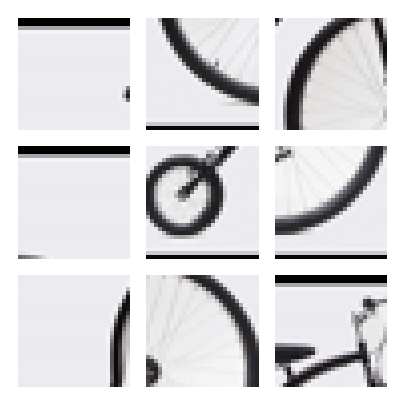

In [11]:
# a[4] is the model input: 9 shuffled patches, placed naively slot 0→pos 0, 1→pos 1, ...
# Note the white cross-hatch: those are the missing border pixels
plot_puzzle(a[4])

# The problem

Your task is to reconstruct the source (96,96) image from the set of 9 scambled patches of dimension (28,28) each.

**The metric used to measure the quality of the reconstruction must be Mean Absolute Error (MAE).**

Compute MAE over the test set, and also return the standard deviation.

As an indicative baseline, let us compute the MAE relative to the mean patches.

In [12]:
def mean_patch_image(patches):
    #input (B,9,28,28,3)
    B = tf.shape(patches)[0] # Corrected: Use batch size from patches input
    # Mean patch
    mean_patch = tf.reduce_mean(patches, axis=1)  # (B, 28, 28, 3)
    # Replicate 9 times
    mean_patches = tf.repeat(
        mean_patch[:, None, :, :, :],
        repeats=9,
        axis=1
    )
    # Reassemble into 96x96 image
    out = tf.reshape(mean_patches, (B, 3, 3, 28, 28, 3))
    out = tf.transpose(out, [0, 1, 3, 2, 4, 5])
    out = tf.reshape(out, (B, 84, 84, 3))
    out = tf.image.resize(out, (96, 96))
    return out

In [13]:
#compute MAE for mean_patch_image using the test_generator
mae = tf.keras.metrics.MeanAbsoluteError()
mae_values = []
for i in range(len(test_generator)):
    a,b = test_generator.__getitem__(i)
    pred = mean_patch_image(a)
    mae_values.append(mae(pred,b))
print("MAE:", tf.reduce_mean(mae_values))
print("std:", tf.math.reduce_std(mae_values))

MAE: tf.Tensor(0.18186162, shape=(), dtype=float32)
std: tf.Tensor(0.0009911107, shape=(), dtype=float32)


# Additional Constraints

* The solution must rely entirely on neural networks and must not contain non-neural algorithmic components. A pipeline of neural networks is allowed.
* Pretrained models are not permitted.
* The total number of trainable parameters must remain below 6 million. The number of parameters of the proposed solution must be reported explicitly.
* The model weights must be made available for download via gdown. Please verify that the provided link works correctly and that the weights can be loaded successfully.
* The solution must be implemented in Keras and must run on Google Colab. Submissions containing notebook execution errors will be penalized.
* The submission must be a single, well documented notebook file. Tar files will be rejected.




# **PROPOSED SOLUTION (LUCA DE ROSA)**

We structure the solution as follows:
1. Data exploration and visualisation;
2. The Model: strategy behind the architecture, definition of the model and training;
3. Final results and conclusions.

# 1. DATA EXPLORATION

Let's have a look at some images

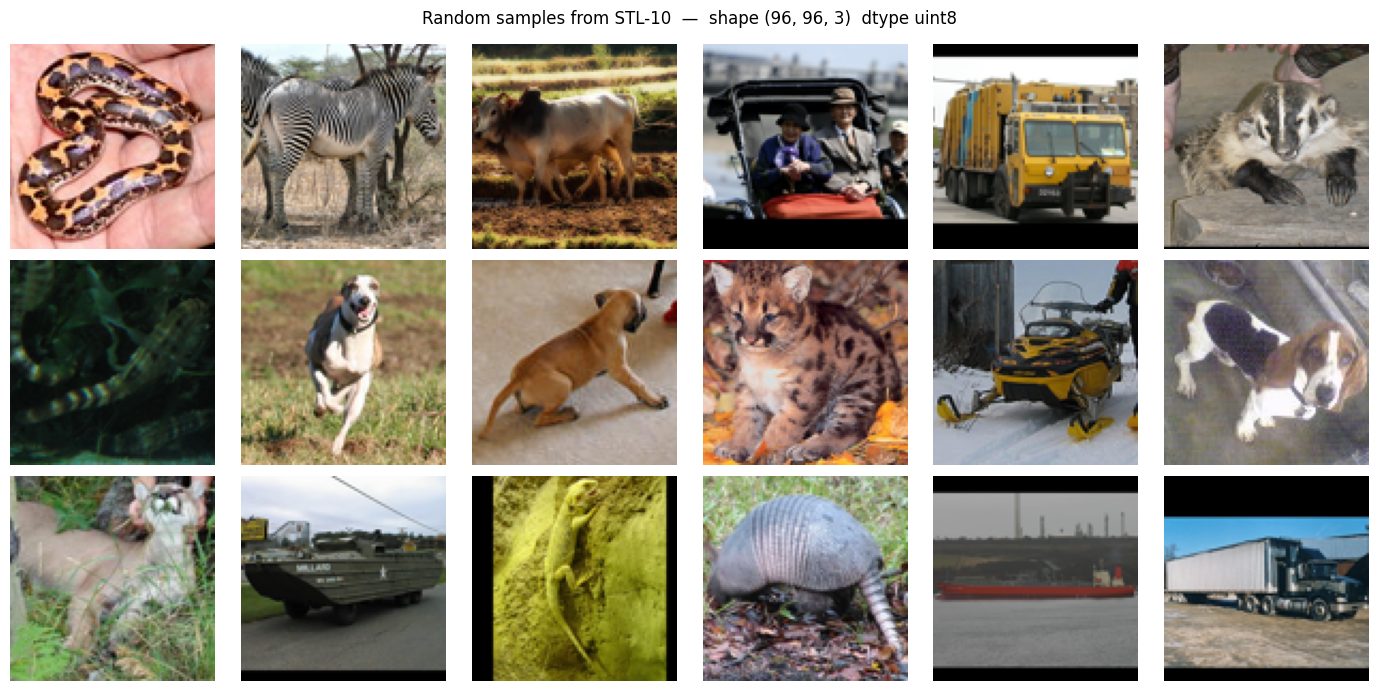

In [14]:
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for ax in axes.flat:
    idx = np.random.randint(len(images))
    ax.imshow(images[idx])
    ax.axis('off')
fig.suptitle(f'Random samples from STL-10  —  shape {images[0].shape}  dtype {images.dtype}', fontsize=12)
plt.tight_layout()
plt.show()

### What are the 9 patches, individually?

The model receives `X` of shape `(batch, 9, 28, 28, 3)`. Let's look at all 9 patches for one example side-by-side with the ground truth image.

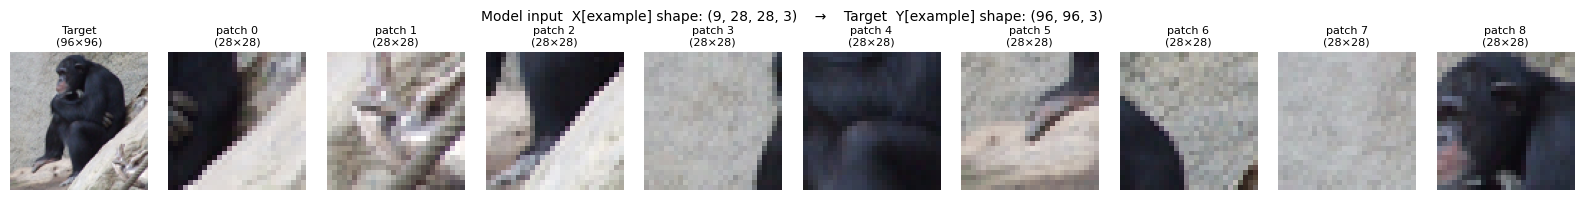

In [15]:
example_idx = 4
patches = a[example_idx]   # (9, 28, 28, 3)
target  = b[example_idx]   # (96, 96, 3)

fig, axes = plt.subplots(1, 10, figsize=(16, 2))

# First column: the target image, resized down visually for comparison
axes[0].imshow(target)
axes[0].set_title('Target\n(96×96)', fontsize=8)
axes[0].axis('off')

# Next 9 columns: each shuffled patch
for i in range(9):
    axes[i + 1].imshow(patches[i])
    axes[i + 1].set_title(f'patch {i}\n(28×28)', fontsize=8)
    axes[i + 1].axis('off')

plt.suptitle('Model input  X[example] shape: (9, 28, 28, 3)    →    Target  Y[example] shape: (96, 96, 3)', fontsize=10)
plt.tight_layout()
plt.show()

### Where are the missing pixels?
Each 28×28 patch sits inside a 32×32 cell. This means we have a **2px eroded border** on each side. When reassembled, those borders form a regular "tic-tac-toe" of missing pixels — **~23% of the image area** that the model must inpaint. We will have to fill in those missing pixels!

Observed pixels : 7056 / 9216  (76.6%)
Missing pixels  : 2160  / 9216  (23.4%)


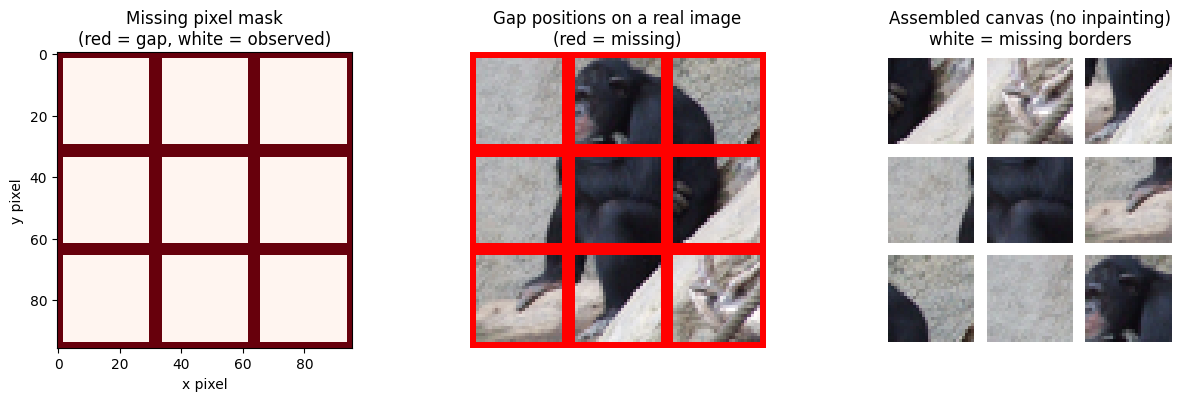

In [16]:
cell_dim  = 32
patch_dim = 28
margin    = (cell_dim - patch_dim) // 2   # = 2

# Build a binary mask: 1 = missing, 0 = observed
missing_mask = np.ones((96, 96), dtype='float32')
for r in range(3):
    for c in range(3):
        y = r * cell_dim + margin
        x = c * cell_dim + margin
        missing_mask[y : y + patch_dim, x : x + patch_dim] = 0.0

n_missing  = int(missing_mask.sum())
n_total    = 96 * 96
n_observed = n_total - n_missing
print(f'Observed pixels : {n_observed} / {n_total}  ({n_observed/n_total:.1%})')
print(f'Missing pixels  : {n_missing}  / {n_total}  ({n_missing/n_total:.1%})')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# 1. The missing pixel mask itself
axes[0].imshow(missing_mask, cmap='Reds', vmin=0, vmax=1)
axes[0].set_title('Missing pixel mask\n(red = gap, white = observed)')
axes[0].set_xlabel('x pixel')
axes[0].set_ylabel('y pixel')

# 2. The mask overlaid on a real image
overlay = target.copy()
overlay[missing_mask == 1] = [1.0, 0.0, 0.0]
axes[1].imshow(overlay)
axes[1].set_title('Gap positions on a real image\n(red = missing)')
axes[1].axis('off')

# 3. The correctly assembled canvas (gaps = white)
canvas = np.ones((96, 96, 3), dtype='float32')
for slot_i in range(9):
    grid_pos = slot_i            # identity ordering
    row = grid_pos // 3
    col = grid_pos % 3
    y = row * cell_dim + margin
    x = col * cell_dim + margin
    canvas[y : y + patch_dim, x : x + patch_dim] = patches[slot_i]
axes[2].imshow(canvas)
axes[2].set_title('Assembled canvas (no inpainting)\nwhite = missing borders')
axes[2].axis('off')

plt.tight_layout()
plt.show()

Starting image VS Patches VS Eroded Patches:

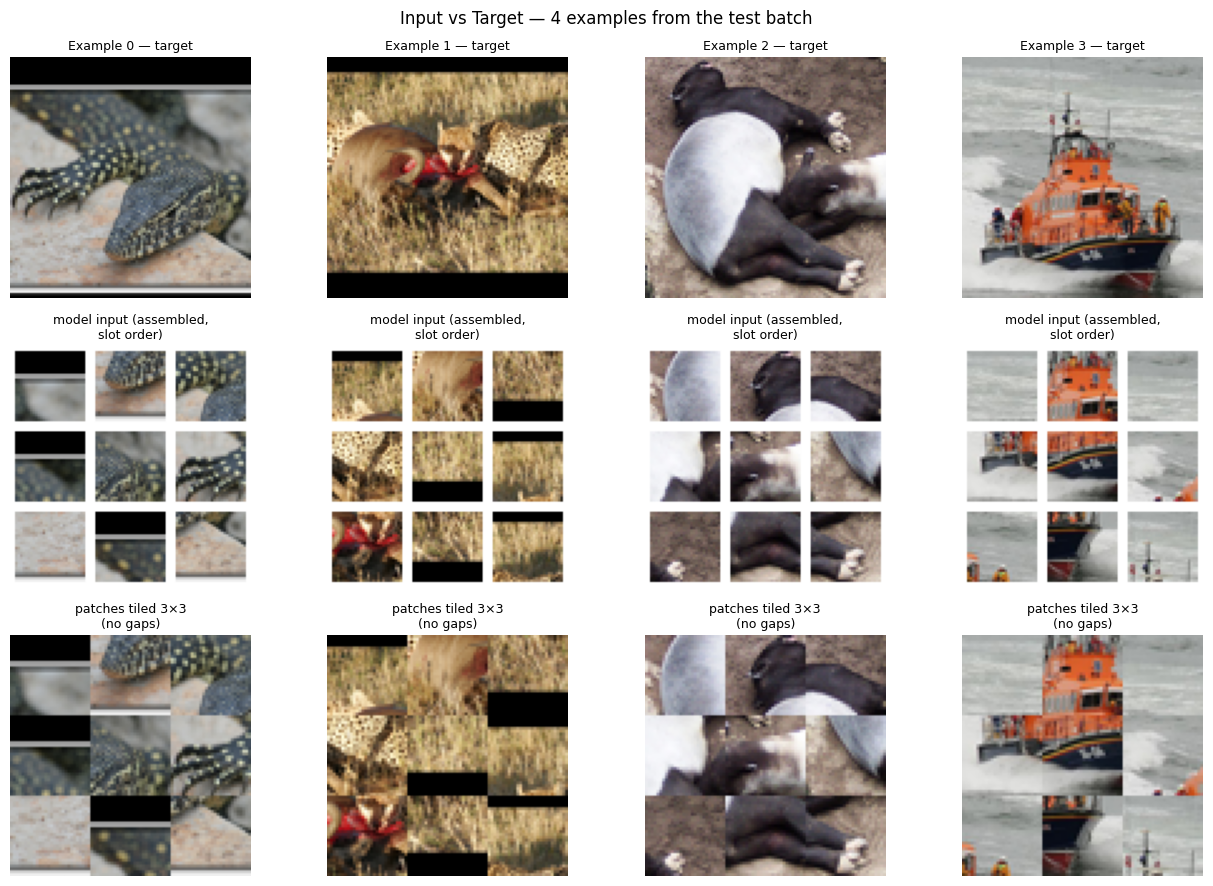

In [17]:
n_examples = 4
fig, axes = plt.subplots(3, n_examples, figsize=(13, 9))

for j in range(n_examples):
    patches_j = a[j]   # (9, 28, 28, 3)
    target_j  = b[j]   # (96, 96, 3)

    # Row 0: ground truth
    axes[0, j].imshow(target_j)
    axes[0, j].set_title(f'Example {j} — target', fontsize=9)
    axes[0, j].axis('off')

    # Row 1: naive assembly (patches placed in slot order, gaps = white)
    canvas = np.ones((96, 96, 3), dtype='float32')
    for slot_i in range(9):
        row = slot_i // 3
        col = slot_i % 3
        y = row * cell_dim + margin
        x = col * cell_dim + margin
        canvas[y : y + patch_dim, x : x + patch_dim] = patches_j[slot_i]
    axes[1, j].imshow(canvas)
    axes[1, j].set_title('model input (assembled,\nslot order)', fontsize=9)
    axes[1, j].axis('off')

    # Row 2: show each patch in a mini-grid
    mini = np.ones((3 * 28, 3 * 28, 3), dtype='float32')
    for k in range(9):
        r, c = divmod(k, 3)
        mini[r*28:(r+1)*28, c*28:(c+1)*28] = patches_j[k]
    axes[2, j].imshow(mini)
    axes[2, j].set_title('patches tiled 3×3\n(no gaps)', fontsize=9)
    axes[2, j].axis('off')

axes[0, 0].set_ylabel('Ground truth', fontsize=10)
axes[1, 0].set_ylabel('Assembled canvas', fontsize=10)
axes[2, 0].set_ylabel('Patches tiled', fontsize=10)

plt.suptitle('Input vs Target — 4 examples from the test batch', fontsize=12)
plt.tight_layout()
plt.show()

### Visualisation of the baseline predictions
This is what `mean_patch_image` actually outputs. For every pixel it takes the mean of all correspondent 9 pixels in each patch. The obtained pattern is repeated across the whole image. Our model must produce something visually better *and* score lower MAE.

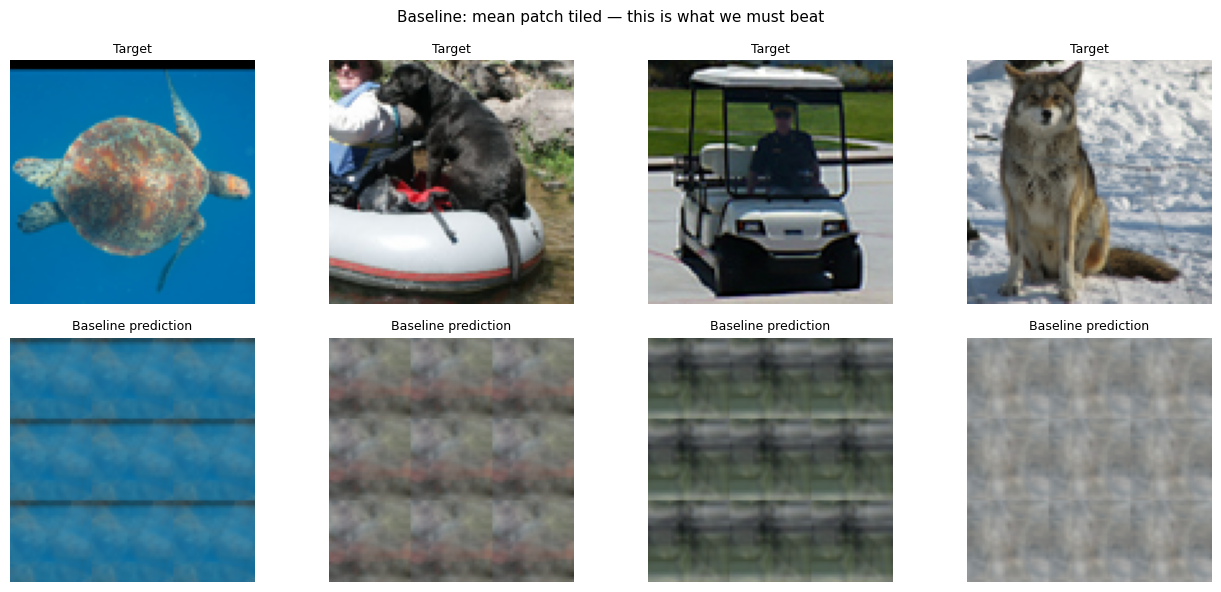

In [18]:
a_vis, b_vis = test_generator.__getitem__(0)
pred_vis = mean_patch_image(a_vis).numpy()

fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for j in range(4):
    axes[0, j].imshow(b_vis[j])
    axes[0, j].set_title('Target', fontsize=9)
    axes[0, j].axis('off')

    axes[1, j].imshow(np.clip(pred_vis[j], 0, 1))
    axes[1, j].set_title('Baseline prediction', fontsize=9)
    axes[1, j].axis('off')

axes[0, 0].set_ylabel('Ground truth', fontsize=10)
axes[1, 0].set_ylabel('Mean-patch baseline', fontsize=10)
plt.suptitle('Baseline: mean patch tiled — this is what we must beat', fontsize=11)
plt.tight_layout()
plt.show()

# 2. THE MODEL

## Architecture

The architecture we implement is inspired by the seminal paper *Attention is all you need* and is based on a simple encoder-decoder transformer, sandwiched between a CNN encoder and a CNN upsampler.

The problem can be decomposed in two sub-problems:

1. **Decide the arrangement**  *where each patch goes*. This is a relational problem: each patch only makes sense next to the others, which is exactly what attention is very good at. The transformer looks at the 9 patches and produces a **soft 9×9 permutation** $P$.
2. **Assemble from real detail.** We then build the image from the patches' **own feature maps**.

More in detail, we can describe the model's architecture as follows:

1. **CNN ENCODING** receives in input $(B,9,28,28,3)$ where $B$ is the batch size, 9 is the number of patches, 28x28 is the resolution of a single patch, and 3 is the number of channels. This block applies a reshape and three convolution layers. It outputs a tensor **$m$** of shape $(B * 9, 28,28,64)$. These are the **feature maps**.
2. We "adjust" the feature map $m$ before feeding it to the encoder transformer block. In particular, we apply GlobalAveragePooling, a reshape and a dense layer with dimension $d = 256$. We obtain as output  a "tokenised version" of $m$ of shape $(B, 9, 256)$.
3. **ENCODER TRANSFORMER BLOCK**. Is a loop repeating three times, each consisting of MultiHeadAttention + Residual + Dense(256). The output is a tensor **$x$** of shape (B, 9, 256).
4. **DECODER TRANSFORMER BLOCK**. Is a loop repeating three times, each consisting of:

  - MultiHeadSelfAttention of $q$ with itself, where $q = Embeddings(9, 256)$ is the positions query. It is a learned vector, and we can think of it as encoding the *things to look for at each of the 9 positions in the 3x3 grid*.
  - MultiHeadCrossAttention(q,x);
  - Dense(256)
  
  Output: Updated q, tensor of shape $(B,9,256)$.

5. **RECONSTRUCTION & UPSAMPLING**. This last stage is the concatenation of:
  - Building the soft-permutation matrix $P$ from $q$ and $x$ using einsum;
  - Apply $P$ to the feature maps $m$ to move patches in the predicted grid cells. As output we obtain a tensor of shape $(B, 84,84,64)$. In this way we are ready for the final upsampling block.
  - Chain of upsampling convolutions to reconstruct the pixel values from the now-ordered features. This outputs a tensor of shape $(B, 96,96,3)$, which is our final output.



In [19]:
D     = 256   # embedding dimension: each patch becomes a length-256 feature vector
HEADS = 8     # attention heads (each head looks at a 256/8 = 32-dim slice)
FFN   = 256   # feed-forward hidden size
# DMAP: channels of the per-patch feature MAP that carries pixel detail. Kept small
# because the map stays at full 28x28 resolution (detail lives in space, not channels).
DMAP  = 64

class EncoderBlock(layers.Layer):
    """One transformer encoder block: self-attention + feed-forward, each wrapped in a
    residual ('skip') connection and LayerNorm.  Input/output shape: (B, 9, D)."""
    def __init__(self, **kw):
        super().__init__(**kw)
        self.attn   = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=0.1)
        self.dense1 = layers.Dense(FFN, activation='relu')
        self.dense2 = layers.Dense(D)
        self.drop   = layers.Dropout(0.1)
        self.norm1  = layers.LayerNormalization()
        self.norm2  = layers.LayerNormalization()

    def call(self, x, training=False):
        # 'x + ...' is the residual skip connection: keep the original vector, ADD the new info
        x = self.norm1(x + self.attn(x, x))                                        # mix patches
        x = self.norm2(x + self.drop(self.dense2(self.dense1(x)), training=training))  # per-vector MLP
        return x

class DecoderBlock(layers.Layer):
    """One transformer decoder block, with TWO attention steps:
       1. self-attention  : the 9 position-queries coordinate with each other
       2. cross-attention : each query reads from the encoded patches (kv) and pulls in
                            the patch that belongs to its grid cell
    q  : (B, 9, D)  the 9 position-queries
    kv : (B, 9, D)  the encoded patches (output of the encoder)"""
    def __init__(self, **kw):
        super().__init__(**kw)
        self.self_attn  = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=0.1)
        self.cross_attn = layers.MultiHeadAttention(HEADS, D // HEADS, dropout=0.1)
        self.dense1 = layers.Dense(FFN, activation='relu')
        self.dense2 = layers.Dense(D)
        self.drop   = layers.Dropout(0.1)
        self.norm1  = layers.LayerNormalization()
        self.norm2  = layers.LayerNormalization()
        self.norm3  = layers.LayerNormalization()

    def call(self, q, kv, training=False):
        q = self.norm1(q + self.self_attn(q, q))    # queries talk to each other
        q = self.norm2(q + self.cross_attn(q, kv))  # queries read from the patches
        q = self.norm3(q + self.drop(self.dense2(self.dense1(q)), training=training))
        return q

In [20]:
class JigsawModel(keras.Model):
    """Single-path 'decide the order, then assemble from real detail', now at FULL patch
       resolution: each patch keeps a 28x28 feature map (no downsampling), so the maximum
       amount of within-patch detail reaches the upsampler. The transformer outputs a soft
       9x9 permutation P; the image is built from the patches' own maps placed by P.
    """
    def __init__(self):
        super().__init__()

        # STAGE 1 - shared CNN. NO strided conv -> the feature MAP stays 28x28 (full detail).
        # We keep few channels (DMAP) because detail now lives in SPACE, not in channels.
        self.patch_cnn = keras.Sequential([
            layers.Conv2D(32,   3, padding='same', activation='relu'),   # 28x28x32
            layers.Conv2D(64,   3, padding='same', activation='relu'),   # 28x28x64
            layers.Conv2D(DMAP, 3, padding='same', activation='relu'),   # 28x28xDMAP
        ])
        self.gap      = layers.GlobalAveragePooling2D()   # map -> one summary, ONLY for reasoning
        self.to_token = layers.Dense(D)                   # project that summary up to D for the transformer

        # STAGE 2-3 - transformer figures out the arrangement of the 9 patches
        self.enc   = [EncoderBlock(name=f'enc{i}') for i in range(3)]
        self.pos_q = layers.Embedding(9, D)
        self.dec   = [DecoderBlock(name=f'dec{i}') for i in range(3)]

        # STAGE 4 - turn the assembled (real, full-res) feature maps into the RGB image
        self.up = keras.Sequential([
            layers.Conv2D(128, 3, padding='same', activation='relu'),   # 84x84  blend the seams
            layers.Conv2D(128, 3, padding='same', activation='relu'),
            layers.Resizing(96, 96),                                    # 84 -> 96 (erosion gap)
            layers.Conv2D(128, 3, padding='same', activation='relu'),   # 96x96
            layers.Conv2D(64,  3, padding='same', activation='relu'),
            layers.Conv2D(3,   1, activation='sigmoid'),                # -> RGB
        ])

    def call(self, patches, training=False):
        # patches: (B, 9, 28, 28, 3)
        B = tf.shape(patches)[0]

        # STAGE 1 - per-patch FULL-RES map (kept) + pooled token (for reasoning)
        m    = self.patch_cnn(tf.reshape(patches, (B * 9, 28, 28, 3)))  # (B*9, 28,28, DMAP)
        maps = tf.reshape(m, (B, 9, 28, 28, DMAP))                     # all the detail, kept
        tok  = self.to_token(tf.reshape(self.gap(m), (B, 9, DMAP)))    # (B, 9, D) summaries

        # STAGE 2 - patches share context
        x = tok
        for block in self.enc:
            x = block(x, training=training)                            # (B, 9, D)

        # STAGE 3 - 9 position-queries; match each position to each patch -> soft permutation
        q = self.pos_q(tf.tile(tf.range(9)[None], [B, 1]))            # (B, 9, D)
        for block in self.dec:
            q = block(q, x, training=training)                        # (B, 9, D)
        # P[b, i, j] = how strongly grid position i wants patch j  (each row sums to 1)
        P = tf.nn.softmax(tf.einsum('bid,bjd->bij', q, x) / (D ** 0.5), axis=-1)  # (B, 9, 9)

        # STAGE 4 - place each patch's REAL 28x28 map into its grid cell -> 84x84 canvas, upsample
        g = tf.einsum('bij,bjhwc->bihwc', P, maps)                    # (B, 9, 28,28, DMAP)
        g = tf.reshape(g, (B, 3, 3, 28, 28, DMAP))
        g = tf.transpose(g, [0, 1, 3, 2, 4, 5])                       # interleave grid + pixels
        g = tf.reshape(g, (B, 84, 84, DMAP))                          # assembled full-res canvas
        return self.up(g)                                            # (B, 96, 96, 3)

In [21]:
model = JigsawModel()
model(tf.zeros((2, 9, 28, 28, 3)))   # build weights

print(f'Parameters: {model.count_params():,} / 6,000,000')
model.summary()

Parameters: 3,683,971 / 6,000,000


Model: "jigsaw_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (18, 28, 28, 64)       │        56,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (2, 9, 256)            │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc0 (EncoderBlock)             │ ?                      │       395,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc1 (EncoderBlock)             │ ?                      │       395,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc2 (EncoderBlock)             │ ?                      │       395,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (2, 9, 256)            │         2,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec0 (DecoderBlock)             │ ?                      │       659,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec1 (DecoderBlock)             │ ?                      │       659,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec2 (DecoderBlock)             │ ?                      │       659,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (2, 96, 96, 3)         │       443,011 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,683,971 (14.05 MB)

 Trainable params: 3,683,971 (14.05 MB)

 Non-trainable params: 0 (0.00 B)

The model seemed to converge steadily but very slowly. Therefore I used a very long training routine to allow the model to plateau, with a variable learning rate and patience, and I ran two training sessions of 50 epochs each, overnight.

In [22]:
train_gen = PatchGenerator(train_images, batch_size=32) #32 default
val_gen   = PatchGenerator(val_images,   batch_size=32) #32 default
do_training = False
if do_training == True:
    SAVE_PATH = 'best_jigsaw.weights.h5'
    EPOCHS = 50
    INITIAL_LR = 3e-4
    MIN_LR = 1e-5
    steps_per_epoch = len(train_gen)
    # Cosine decay: smoothly anneals lr from INITIAL_LR down to MIN_LR over all
    # training steps
    lr_schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate = INITIAL_LR,
        decay_steps           = EPOCHS * steps_per_epoch,
        alpha                 = MIN_LR / INITIAL_LR   # minimum lr as fraction
        # of initial
    )

    callbacks = [
        # stop early if val_loss has not improved for 15 epochs, restore best
        # weights in memory
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=15, restore_best_weights=True,
            verbose=1
        ),
        # also save best weights to disk (safe if Colab disconnects overnight)
        keras.callbacks.ModelCheckpoint(SAVE_PATH, monitor = 'val_loss',
            save_best_only = True, save_weights_only = True, verbose = 1
        ),
    ]


    model.compile(optimizer=keras.optimizers.Adam(lr_schedule), loss='mae')

    history = model.fit(
        train_gen, validation_data=val_gen,
        epochs=EPOCHS, callbacks=callbacks
    )


### Importing Weights from Gdown

In [23]:
load_weights = True
if load_weights == True:
    file_id = '1IvwsIPkWI1gadBxiJ9DTV9N1jHTtxGpZ'
    weights_path = 'lucaderosa_downloaded_weights.weights.h5'
    gdown.download(f'https://drive.google.com/uc?id={file_id}', weights_path, quiet=False)
    model.load_weights(weights_path)

Downloading...
From: https://drive.google.com/uc?id=1IvwsIPkWI1gadBxiJ9DTV9N1jHTtxGpZ
To: /content/lucaderosa_downloaded_weights.weights.h5
100%|██████████| 44.6M/44.6M [00:00<00:00, 81.3MB/s]


# 3. Results and Conclusion

In [24]:
# Final evaluation, using exactly the same procedure as the baseline provided,
# so the model's score is directly comparable to the mean-patch baseline above.

#Note: can take up to 5 minutes to run.
mae = tf.keras.metrics.MeanAbsoluteError()
mae_values = []
for i in range(len(test_generator)):
    a, b = test_generator.__getitem__(i)
    pred = model(a, training=False)        # was mean_patch_image(a) for the baseline
    mae_values.append(mae(pred, b))
print("MAE:", tf.reduce_mean(mae_values))
print("std:", tf.math.reduce_std(mae_values))


MAE: tf.Tensor(0.051203627, shape=(), dtype=float32)
std: tf.Tensor(0.00066197966, shape=(), dtype=float32)


- The MAE on the test set is around $0.0512$, with standard deviation $\sim 0.0006$;
- The total number of trainable parameters of this model is $3,683,971$ (≈ 3.7M), comfortably under the 6M limit.
- Convergence was slow and steady, requiring long training runs. This made time a real design bottleneck;
- As potential improvements, I would next try to implement a sharper inpainting using a different more aggressive loss. It was interesting to note how adding more attention heads worsened model performance. Probably the model started to overfit by paying attention to non-meaningful relations between patches features, resulting in more frequent mismatches.

Let's visualise how the model does!

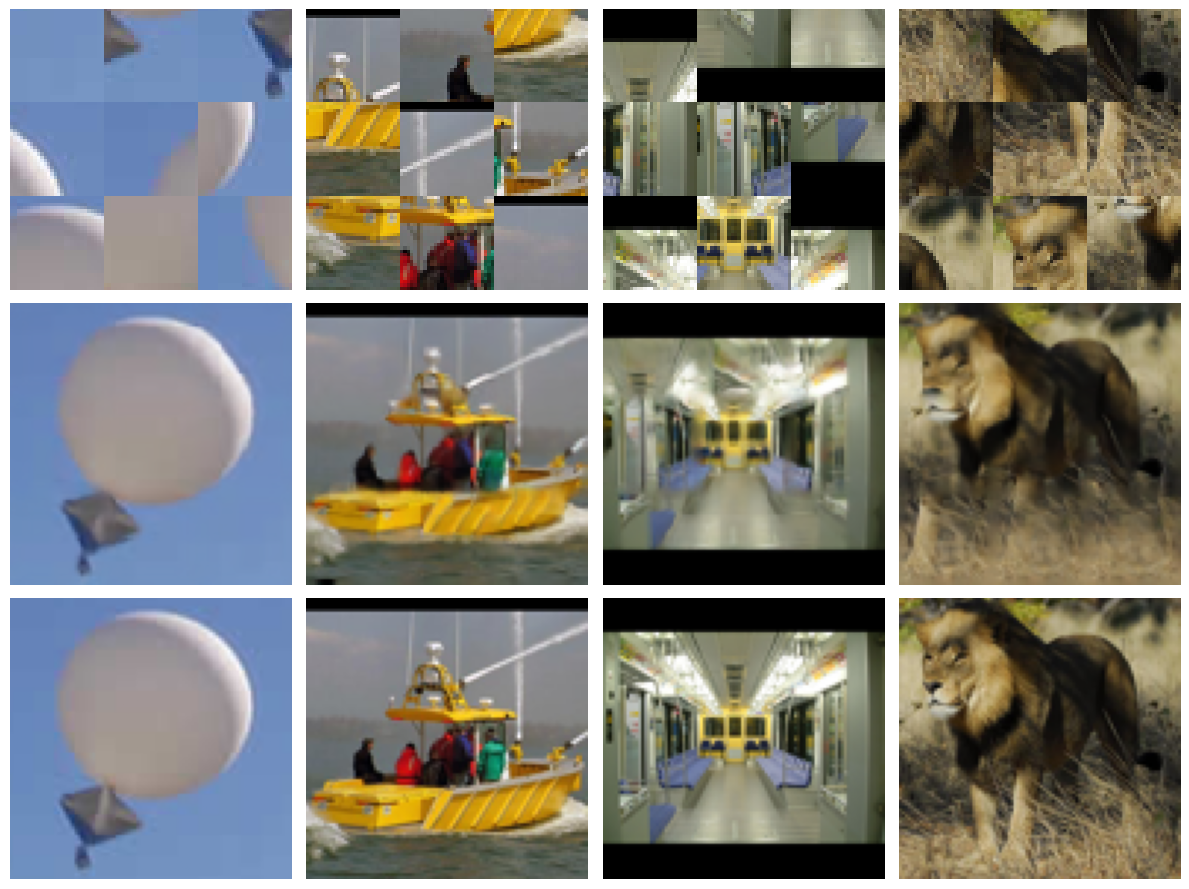

In [31]:
# visual check: shuffled input | prediction | ground truth
X_b, Y_b = PatchGenerator(test_images, batch_size=8)[0]
pred = model.predict(X_b, verbose=0)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for j in range(4):
    tile = np.ones((84, 84, 3), dtype='float32')
    for k in range(9):
        r, c = divmod(k, 3)
        tile[r*28:(r+1)*28, c*28:(c+1)*28] = X_b[j, k]
    axes[0, j].imshow(tile);   axes[0, j].axis('off')
    axes[1, j].imshow(pred[j]); axes[1, j].axis('off')
    axes[2, j].imshow(Y_b[j]); axes[2, j].axis('off')

axes[0,0].set_ylabel('input (tiled)')
axes[1,0].set_ylabel('prediction')
axes[2,0].set_ylabel('ground truth')
plt.tight_layout(); plt.show()